# 2. Finding arbitrage cycles across many pools

Tokens are nodes; each pool contributes two directed edges with weight `-log(g R_out / R_in)`. A cycle with negative total weight multiplies money by more than 1, so **Bellman-Ford** finds it. The trade size along the cycle uses the same closed form as notebook 1 (compose one Moebius map per hop).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from amm import *
INK, INDIGO, AMBER, GREEN, CORAL, GREY = "#0E1A2B", "#4B3FE4", "#E8982B", "#0E9F7E", "#E5484D", "#8A94A6"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "font.size": 10, "axes.grid": True, "grid.color": "#E3E7EE", "grid.linewidth": .7, "axes.axisbelow": True})

## A six-token market with a hidden loop

In [2]:
import math
tokens = ["USD", "ETH", "BTC", "SOL", "ARB", "OP"]
fair = {"USD": 1.0, "ETH": 2000.0, "BTC": 40000.0, "SOL": 100.0, "ARB": 1.0, "OP": 2.0}   # reference prices in USD
def mk(a, b, tvl, skew=1.0, fee=0.003):
    # depth tvl/2 per side at fair prices, token b side multiplied by skew (mispricing)
    return Pool(a, b, tvl / 2 / fair[a], tvl / 2 / fair[b] * skew, fee)
pools = [mk("USD", "ETH", 4e6), mk("ETH", "BTC", 3e6, 1.00), mk("BTC", "USD", 3e6, 1.00),
         mk("ETH", "SOL", 1e6, 1.04), mk("SOL", "USD", 1e6, 1.00), mk("ARB", "USD", 5e5), mk("OP", "ARB", 4e5, 1.00),
         mk("OP", "USD", 4e5, 1.0, fee=0.01)]
cyc = find_negative_cycle(pools)
print("Bellman-Ford found:", " -> ".join(f"{t}[pool {i}]" for i, t, _ in cyc), "->", cyc[0][1])
t = size_cycle(pools, cyc)
print(f"marginal round-trip multiplier: {t.rate:.5f}")
print(f"optimal input {t.amount_in:,.4f} {t.start_token}, profit {t.profit:,.4f} {t.start_token}")

Bellman-Ford found: SOL[pool 4] -> USD[pool 0] -> ETH[pool 3] -> SOL
marginal round-trip multiplier: 1.03067
optimal input 34.0220 SOL, profit 0.5178 SOL


## Repeat until the market is flat

In [3]:
trades, flat = arbitrage_until_flat(pools)
print(f"{len(trades)} trades until no negative cycle remained")
for k, tr in enumerate(trades, 1):
    path = " -> ".join(t_ for _, t_, _ in tr.cycle) + " -> " + tr.cycle[0][1]
    print(f"{k}. {path:<28} in {tr.amount_in:>12,.4f} {tr.start_token:<3}  profit {tr.profit:>10,.4f}  (marginal x{tr.rate:.5f})")
from amm.cycles import cycle_rate
print("remaining negative cycle:", find_negative_cycle(flat))
print("k never fell:", all(b.k >= a.k for a, b in zip(pools, flat)))

2 trades until no negative cycle remained
1. SOL -> USD -> ETH -> SOL     in      34.0220 SOL  profit     0.5178  (marginal x1.03067)
2. SOL -> USD -> BTC -> ETH -> SOL in       0.2982 SOL  profit     0.0000  (marginal x1.00031)
remaining negative cycle: None
k never fell: True


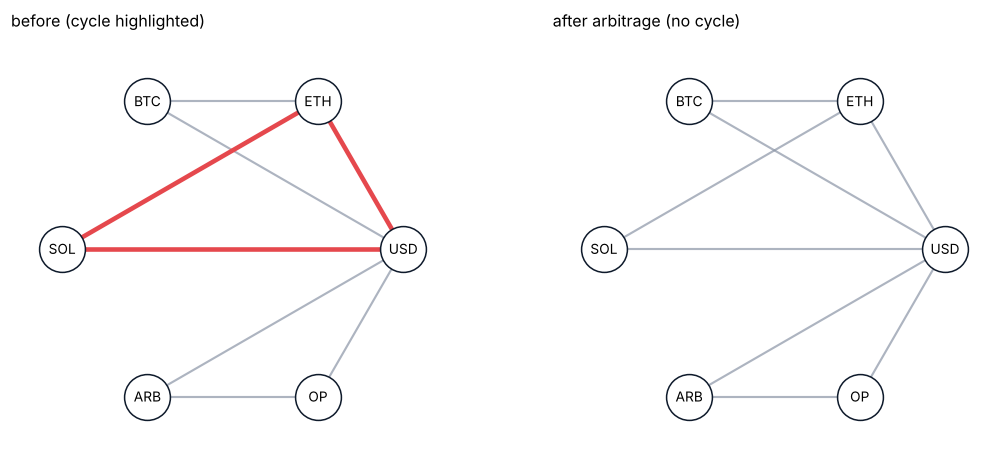

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
ang = {t_: 2 * math.pi * i / len(tokens) for i, t_ in enumerate(tokens)}
pos = {t_: (math.cos(a), math.sin(a)) for t_, a in ang.items()}
for ax, ps, title in [(axes[0], pools, "before"), (axes[1], flat, "after arbitrage")]:
    c = find_negative_cycle(ps); on = {(i, t_) for i, t_, _ in c} if c else set()
    for i, p in enumerate(ps):
        (x0, y0), (x1, y1) = pos[p.token0], pos[p.token1]
        hot = any(i == j for j, _ in on)
        ax.plot([x0, x1], [y0, y1], color=CORAL if hot else GREY, lw=3 if hot else 1.4, alpha=1 if hot else .7, zorder=1)
    for t_, (x, y) in pos.items():
        ax.scatter([x], [y], s=900, color="white", edgecolor=INK, zorder=3); ax.text(x, y, t_, ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title + (" (cycle highlighted)" if c else " (no cycle)"), loc="left", fontsize=10.5); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.25, 1.25); ax.axis("off"); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig("../assets/cycle_network.png", dpi=150); plt.show()

## Does Bellman-Ford agree with exhaustive search?

In [5]:
import random, time
def random_market(rng, n_tokens, n_pools, mis=0.004):
    toks = [f"T{i}" for i in range(n_tokens)]; px = {t_: math.exp(rng.gauss(0, 1)) for t_ in toks}; out = []
    for _ in range(n_pools):
        a, b = rng.sample(toks, 2); d = rng.uniform(1e3, 1e5)
        out.append(Pool(a, b, d / px[a], d * math.exp(rng.gauss(0, mis)) / px[b]))
    return out
rng = random.Random(1); agree = found = 0; N = 1000
for _ in range(N):
    ps = random_market(rng, 6, 9)
    bf = find_negative_cycle(ps); ex = best_cycle(ps, max_len=6)
    agree += (bf is not None) == (ex is not None); found += ex is not None
print(f"{N} random markets (6 tokens, 9 pools): detection agrees in {agree}/{N}; arbitrage exists in {found}")

1000 random markets (6 tokens, 9 pools): detection agrees in 1000/1000; arbitrage exists in 735


## Scaling

In [6]:
rng = random.Random(3); rows = []
for n_tok in (10, 50, 200, 800):
    ps = random_market(rng, n_tok, 4 * n_tok); t0 = time.perf_counter(); find_negative_cycle(ps); dt = time.perf_counter() - t0
    rows.append((n_tok, 4 * n_tok, dt * 1e3))
print("tokens  pools  Bellman-Ford time (ms)")
for n, m, ms in rows: print(f"{n:>6} {m:>6} {ms:>10.1f}")

tokens  pools  Bellman-Ford time (ms)
    10     40        0.2
    50    200        9.0
   200    800      125.2
   800   3200     2345.7
